# SVM para EngineFaultDB
Clasificación multiclase de fallas (Fault 0–3): validación cruzada, búsqueda de hiperparámetros, IC 95 % y métricas train/val/test.

In [1]:
# Cargar el CSV en Colab
# Opción A: subir el archivo manualmente
from google.colab import files
uploaded = files.upload()   # selecciona EngineFaultDB_Final.csv
CSV_PATH = 'EngineFaultDB_Final.csv'

# Opción B: desde Google Drive (descomenta)
# from google.colab import drive
# drive.mount('/content/drive')
# CSV_PATH = '/content/drive/MyDrive/EngineFaultDB_Final.csv'

Saving EngineFaultDB_Final.csv to EngineFaultDB_Final.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

RANDOM_STATE = 42
N_FOLDS = 5
TUNE_SUBSAMPLE = 15000   # None para usar todo el train en el ajuste (lento con SVM)

## 1. Datos

In [3]:
df = pd.read_csv(CSV_PATH)
X = df.drop(columns=["Fault"])
y = df["Fault"]

# Opcional: quitar variables redundantes (corr ~1.0: RPM-Speed, Lambda-AFR)
# X = X.drop(columns=["RPM", "AFR"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

## 2. Modelo

In [4]:
# El escalador va DENTRO del pipeline para que se ajuste solo con cada fold
# de entrenamiento (evita fuga de informacion hacia validacion).
pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(class_weight="balanced", random_state=RANDOM_STATE)),
])

# Malla de hiperparametros (esta es la tabla que pide la guia)
param_grid = [
    {"svm__kernel": ["linear"],
     "svm__C": [0.01, 0.1, 1, 10, 100]},
    {"svm__kernel": ["rbf"],
     "svm__C": [0.1, 1, 10, 100],
     "svm__gamma": [0.001, 0.01, 0.1, 1]},
    {"svm__kernel": ["poly"],
     "svm__C": [0.1, 1, 10],
     "svm__degree": [2, 3],
     "svm__gamma": ["scale"]},
]

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# Submuestra para acelerar la busqueda (el modelo final se reentrena con todo el train)
if TUNE_SUBSAMPLE and TUNE_SUBSAMPLE < len(X_train):
    X_tune, _, y_tune, _ = train_test_split(
        X_train, y_train, train_size=TUNE_SUBSAMPLE,
        stratify=y_train, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train, y_train

grid = GridSearchCV(
    pipe, param_grid, cv=cv, scoring="f1_macro",
    n_jobs=-1, verbose=1, return_train_score=True, refit=True)
grid.fit(X_tune, y_tune)

print("Mejores hiperparametros:", grid.best_params_)
print(f"Mejor F1-macro (CV): {grid.best_score_:.4f}")

# Tabla completa de resultados de la malla
res = pd.DataFrame(grid.cv_results_)
cols = ["param_svm__kernel", "param_svm__C", "param_svm__gamma", "param_svm__degree",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
res_table = res[cols].sort_values("rank_test_score")
print(res_table.head(10).to_string(index=False))
res_table.to_csv("svm_grid_results.csv", index=False)

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Mejores hiperparametros: {'svm__C': 100, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
Mejor F1-macro (CV): 0.7588
param_svm__kernel  param_svm__C param_svm__gamma  param_svm__degree  mean_train_score  mean_test_score  std_test_score  rank_test_score
              rbf         100.0                1                NaN          0.850546         0.758782        0.002699                1
              rbf          10.0                1                NaN          0.812402         0.755520        0.003618                2
              rbf           1.0                1                NaN          0.776123         0.749624        0.004660                3
              rbf         100.0              0.1                NaN          0.776366         0.747777        0.006466                4
              rbf          10.0              0.1                NaN          0.757155         0.740462        0.007527                5
              

## 3. Modelo final (todo el train)

In [5]:
best_params = {k.replace("svm__", ""): v for k, v in grid.best_params_.items()}
final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(class_weight="balanced", random_state=RANDOM_STATE, **best_params)),
])

## 4. Validacion cruzada con IC al 95 %

In [6]:
scoring = {"accuracy": "accuracy",
           "precision": "precision_macro",
           "recall": "recall_macro",
           "f1": "f1_macro"}
cv_res = cross_validate(final_model, X_train, y_train, cv=cv, scoring=scoring,
                        return_train_score=True, n_jobs=-1)

def mean_ci(values, conf=0.95):
    values = np.asarray(values)
    m = values.mean()
    h = stats.sem(values) * stats.t.ppf((1 + conf) / 2, len(values) - 1)
    return m, h

print("\n=== Validacion cruzada (media ± IC 95 %) ===")
summary = []
for name in scoring:
    tr_m, tr_h = mean_ci(cv_res[f"train_{name}"])
    va_m, va_h = mean_ci(cv_res[f"test_{name}"])
    summary.append([name, f"{tr_m:.4f} ± {tr_h:.4f}", f"{va_m:.4f} ± {va_h:.4f}"])
summary_df = pd.DataFrame(summary, columns=["Metrica", "Train", "Validacion"])
print(summary_df.to_string(index=False))


=== Validacion cruzada (media ± IC 95 %) ===
  Metrica           Train      Validacion
 accuracy 0.8105 ± 0.0010 0.7518 ± 0.0034
precision 0.8227 ± 0.0013 0.7630 ± 0.0038
   recall 0.8191 ± 0.0009 0.7623 ± 0.0035
       f1 0.8154 ± 0.0011 0.7582 ± 0.0028


## 5. Test final

In [7]:
final_model.fit(X_train, y_train)
y_pred_test = final_model.predict(X_test)

print("\n=== Test ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_test):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_test, average='macro'):.4f}")
print(f"F1-macro : {f1_score(y_test, y_pred_test, average='macro'):.4f}")
print(classification_report(y_test, y_pred_test, digits=4))

# IC del test por bootstrap (accuracy)
rng = np.random.default_rng(RANDOM_STATE)
yt, yp = y_test.to_numpy(), y_pred_test
boot = [accuracy_score(yt[i], yp[i])
        for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Accuracy test IC 95 % (bootstrap): [{lo:.4f}, {hi:.4f}]")


=== Test ===
Accuracy : 0.7462
Precision: 0.7580
Recall   : 0.7574
F1-macro : 0.7513
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000      3200
           1     1.0000    1.0000    1.0000      2200
           2     0.5378    0.3750    0.4419      3000
           3     0.4943    0.6546    0.5633      2800

    accuracy                         0.7462     11200
   macro avg     0.7580    0.7574    0.7513     11200
weighted avg     0.7498    0.7462    0.7413     11200

Accuracy test IC 95 % (bootstrap): [0.7383, 0.7543]


## 6. Graficas

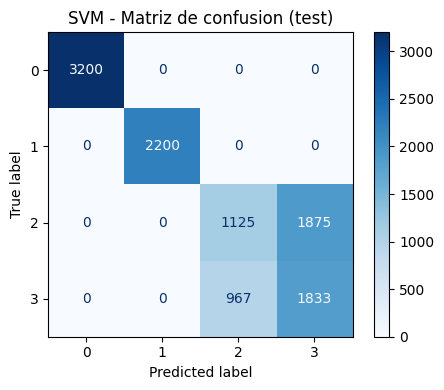

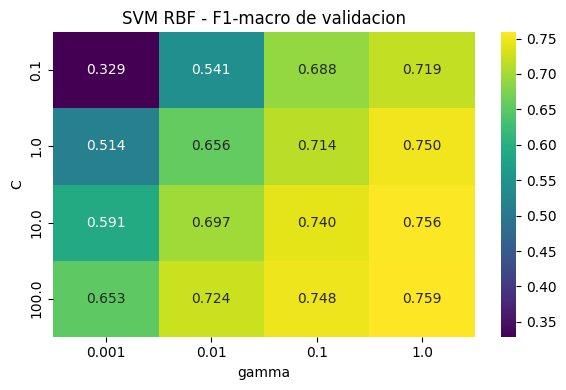

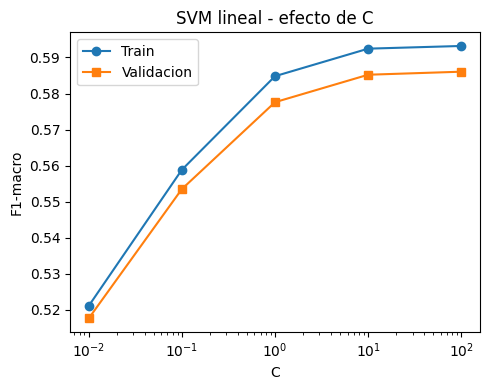

In [8]:
# Matriz de confusion
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_test)).plot(ax=ax, cmap="Blues")
ax.set_title("SVM - Matriz de confusion (test)")
plt.tight_layout(); plt.savefig("svm_confusion.png", dpi=150); plt.show()

# Efecto de C y gamma en el kernel RBF (F1 de validacion)
rbf = res[res["param_svm__kernel"] == "rbf"].copy()
if not rbf.empty:
    heat = rbf.pivot(index="param_svm__C", columns="param_svm__gamma",
                     values="mean_test_score").astype(float)
    plt.figure(figsize=(6, 4))
    sns.heatmap(heat, annot=True, fmt=".3f", cmap="viridis")
    plt.xlabel("gamma"); plt.ylabel("C")
    plt.title("SVM RBF - F1-macro de validacion")
    plt.tight_layout(); plt.savefig("svm_rbf_heatmap.png", dpi=150); plt.show()

# Efecto de C en el kernel lineal (train vs validacion)
lin = res[res["param_svm__kernel"] == "linear"].sort_values("param_svm__C")
if not lin.empty:
    plt.figure(figsize=(5, 4))
    plt.semilogx(lin["param_svm__C"].astype(float), lin["mean_train_score"], "o-", label="Train")
    plt.semilogx(lin["param_svm__C"].astype(float), lin["mean_test_score"], "s-", label="Validacion")
    plt.xlabel("C"); plt.ylabel("F1-macro"); plt.legend()
    plt.title("SVM lineal - efecto de C")
    plt.tight_layout(); plt.savefig("svm_linear_C.png", dpi=150); plt.show()

```markdown
## 7. Reducción de Dimensionalidad (PCA y UMAP)
Vamos a reducir la dimensión de las características a 2D utilizando **PCA** (lineal) y **UMAP** (no lineal) para visualizar de manera directa el solapamiento entre las clases de fallas (especialmente entre las clases 2 y 3).
```

In [9]:
# Instalar biblioteca UMAP
!pip install umap-learn -q

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


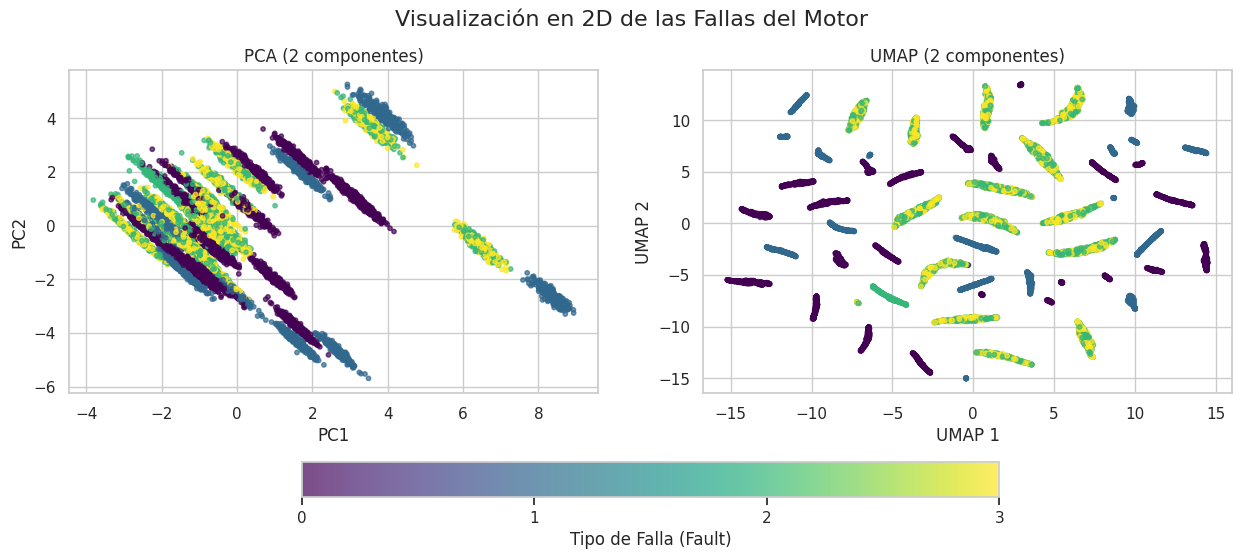

In [15]:
import umap
from sklearn.decomposition import PCA

# Escalar los datos previamente para asegurar consistencia
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)

# Tomamos una submuestra aleatoria para acelerar la visualización y renderizado de UMAP
# ya que graficar 44,000 puntos puede saturar la visualización
np.random.seed(RANDOM_STATE)
subsample_idx = np.random.choice(len(X_scaled), size=15000, replace=False)
X_sub = X_scaled[subsample_idx]
y_sub = y_train.iloc[subsample_idx].values

# --- 1. PCA ---
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sub)

# --- 2. UMAP ---
umap_reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)
X_umap = umap_reducer.fit_transform(X_sub)

# --- Graficar resultados ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Grafica PCA
scatter_pca = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y_sub, cmap='viridis', s=10, alpha=0.7)
axes[0].set_title("PCA (2 componentes)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# Grafica UMAP
scatter_umap = axes[1].scatter(X_umap[:, 0], X_umap[:, 1], c=y_sub, cmap='viridis', s=10, alpha=0.7)
axes[1].set_title("UMAP (2 componentes)")
axes[1].set_xlabel("UMAP 1")
axes[1].set_ylabel("UMAP 2")

# Añadir barra de color
cbar = fig.colorbar(scatter_umap, ax=axes, orientation='horizontal', pad=0.15, shrink=0.6)
cbar.set_label('Tipo de Falla (Fault)')
cbar.set_ticks([0, 1, 2, 3])

plt.suptitle("Visualización en 2D de las Fallas del Motor", fontsize=16)
plt.savefig("pca_umap_visualization.png", dpi=150, bbox_inches='tight')
plt.show()

```markdown
## 8. Análisis Comparativo de las Características Originales
Antes de proyectar con PCA o UMAP, analizamos la relevancia de cada característica física original utilizando correlación y un clasificador basado en árboles (Random Forest) para determinar su importancia relativa.
```

In [11]:
from sklearn.ensemble import RandomForestClassifier

# 1. Calcular correlación de Spearman absoluta con la variable objetivo
correlations = df.corr(method='spearman')['Fault'].abs().drop('Fault')

# 2. Entrenar un Random Forest rápido para extraer importancia de características
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
importances = rf.feature_importances_

# 3. Crear DataFrame comparativo
feature_comparison = pd.DataFrame({
    'Correlación_Abs_Spearman': correlations,
    'Importancia_Random_Forest': importances
}, index=X.columns)

# Normalizar métricas para facilitar comparación visual de rankings
feature_comparison['Ranking_Correlacion'] = feature_comparison['Correlación_Abs_Spearman'].rank(ascending=False).astype(int)
feature_comparison['Ranking_Random_Forest'] = feature_comparison['Importancia_Random_Forest'].rank(ascending=False).astype(int)

feature_comparison = feature_comparison.sort_values(by='Importancia_Random_Forest', ascending=False)

print("=== Tabla Comparativa de Importancia de Características original ===")
display(feature_comparison)

=== Tabla Comparativa de Importancia de Características original ===


,Correlación_Abs_Spearman,Importancia_Random_Forest,Ranking_Correlacion,Ranking_Random_Forest
CO,0.285114,0.119257,2,1
Force,0.173133,0.110746,9,2
Consumption L/100KM,0.255960,0.089552,3,3
Power,0.112786,0.084059,10,4
HC,0.377696,0.083265,1,5
Consumption L/H,0.094854,0.081365,11,6
Speed,0.238666,0.071906,5,7
RPM,0.239179,0.069666,4,8
O2,0.068443,0.069252,13,9
CO2,0.180815,0.061365,8,10


```markdown
## 9. Evaluación del Modelo SVM con Extracción de Características (PCA 2D)
Entrenamos el clasificador SVM optimizado utilizando únicamente las 2 componentes principales proyectadas por PCA para medir su capacidad predictiva en baja dimensionalidad.
```

=== Resultados SVM usando extracción por PCA (2 Componentes) ===
Accuracy : 0.6788
F1-macro : 0.6472

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9008    0.9394    0.9197      3200
           1     0.7891    0.9441    0.8597      2200
           2     0.5611    0.1500    0.2367      3000
           3     0.4674    0.7393    0.5727      2800

    accuracy                         0.6788     11200
   macro avg     0.6796    0.6932    0.6472     11200
weighted avg     0.6795    0.6788    0.6382     11200



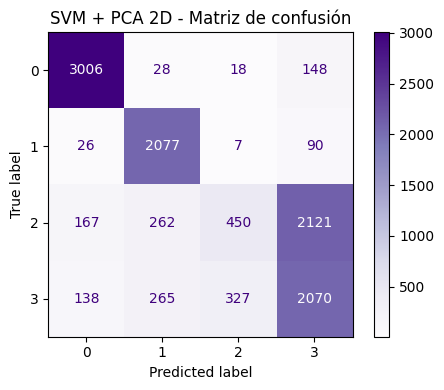

In [12]:
# Crear un pipeline específico que incluye escalador, reducción por PCA (2 componentes) y SVM
pca_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE)),
    ("svm", SVC(class_weight="balanced", random_state=RANDOM_STATE, **best_params))
])

# Entrenar utilizando todo el conjunto de entrenamiento
pca_svm_pipeline.fit(X_train, y_train)

# Predecir en el conjunto de prueba
y_pred_pca = pca_svm_pipeline.predict(X_test)

# Imprimir resultados del rendimiento
print("=== Resultados SVM usando extracción por PCA (2 Componentes) ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_pca):.4f}")
print(f"F1-macro : {f1_score(y_test, y_pred_pca, average='macro'):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_pca, digits=4))

# Mostrar Matriz de Confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_pca)).plot(ax=ax, cmap="Purples")
ax.set_title("SVM + PCA 2D - Matriz de confusión")
plt.tight_layout()
plt.show()

```markdown
## 10. Evaluación del Modelo SVM con Extracción de Características (UMAP 2D)
Entrenamos y evaluamos el clasificador SVM optimizado utilizando únicamente las 2 componentes no lineales proyectadas por UMAP para analizar si mejora la separación de las clases más complejas.
```

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


=== Resultados SVM usando extracción por UMAP (2 Componentes) ===
Accuracy : 0.7329
F1-macro : 0.7406

Reporte de Clasificación:
              precision    recall  f1-score   support

           0     0.9619    0.9856    0.9736      3200
           1     0.9903    0.9755    0.9828      2200
           2     0.5223    0.5143    0.5183      3000
           3     0.4879    0.4879    0.4879      2800

    accuracy                         0.7329     11200
   macro avg     0.7406    0.7408    0.7406     11200
weighted avg     0.7312    0.7329    0.7320     11200



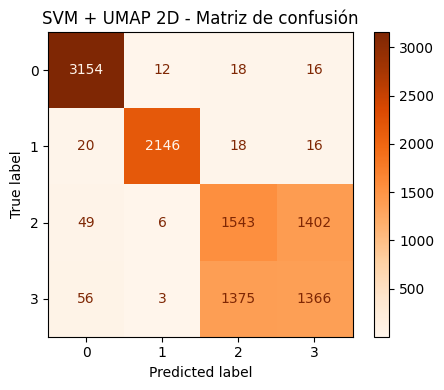

In [13]:
# Crear un pipeline específico que incluye escalador, reducción por UMAP (2 componentes) y SVM
# Nota: UMAP requiere umap-learn instalado previamente en el entorno de ejecución.
umap_svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("umap", umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE)),
    ("svm", SVC(class_weight="balanced", random_state=RANDOM_STATE, **best_params))
])

# Entrenar utilizando todo el conjunto de entrenamiento
# (Nota: UMAP puede tardar un poco más en ajustarse que PCA debido a su naturaleza iterativa no lineal)
umap_svm_pipeline.fit(X_train, y_train)

# Predecir en el conjunto de prueba
y_pred_umap = umap_svm_pipeline.predict(X_test)

# Imprimir resultados del rendimiento
print("=== Resultados SVM usando extracción por UMAP (2 Componentes) ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_umap):.4f}")
print(f"F1-macro : {f1_score(y_test, y_pred_umap, average='macro'):.4f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_umap, digits=4))

# Mostrar Matriz de Confusión
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_umap)).plot(ax=ax, cmap="Oranges")
ax.set_title("SVM + UMAP 2D - Matriz de confusión")
plt.tight_layout()
plt.show()

```markdown
## 11. Comparativa de Rendimiento (Original vs. PCA vs. UMAP)

Presentamos una comparación directa de las métricas obtenidas en el conjunto de prueba para evaluar el impacto de la reducción de dimensionalidad lineal y no lineal en el rendimiento de nuestro clasificador SVM optimizado:

* **Modelo SVM Completo (14 Variables):**
  * **Accuracy:** 74.62%
  * **F1-macro:** 75.13%
  * *Análisis:* Define el límite superior de rendimiento (*baseline*). Mantiene una clasificación perfecta para las fallas fáciles (0 y 1), pero sufre para desagregar las fallas 2 y 3 debido al fuerte solapamiento físico de los sensores.

* **SVM con Extracción PCA (2 Componentes Lineales):**
  * **Accuracy:** 67.88% ($\downarrow$ 6.74% respecto al modelo completo)
  * **F1-macro:** 64.72% ($\downarrow$ 10.41% respecto al modelo completo)
  * *Análisis:* La proyección lineal colapsa la separabilidad de las clases complejas. El recall de la **Falla 2 cae dramáticamente al 15%**, lo que demuestra que un espacio bidimensional lineal es insuficiente para modelar los límites de decisión de este motor.

* **SVM con Extracción UMAP (2 Componentes No Lineales):**
  * **Accuracy:** 73.29% ($\downarrow$ 1.33% respecto al modelo completo)
  * **F1-macro:** 74.06% ($\downarrow$ 1.07% respecto al modelo completo)
  * *Análisis:* UMAP demuestra un comportamiento sobresaliente al preservar las relaciones de vecindad no lineales. Con solo **2 componentes**, recupera casi la totalidad de la capacidad predictiva del modelo completo, elevando el recall de la **Falla 2 al 51.43%** y logrando un balance óptimo entre complejidad computacional y rendimiento.
```

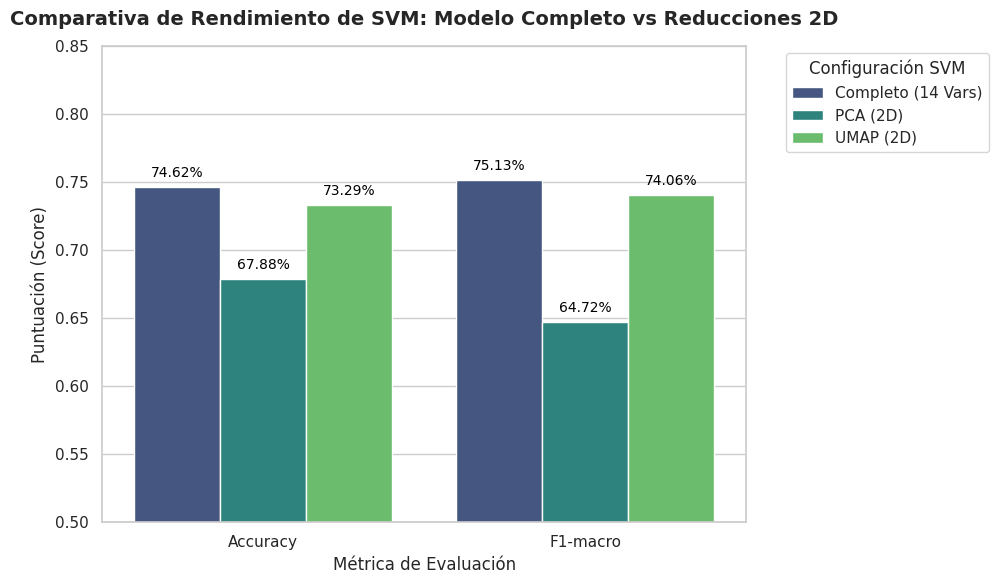

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Definición de los resultados de cada configuración
resultados_data = {
    'Modelo': ['Completo (14 Vars)', 'PCA (2D)', 'UMAP (2D)', 'Completo (14 Vars)', 'PCA (2D)', 'UMAP (2D)'],
    'Métrica': ['Accuracy', 'Accuracy', 'Accuracy', 'F1-macro', 'F1-macro', 'F1-macro'],
    'Valor': [0.7462, 0.6788, 0.7329, 0.7513, 0.6472, 0.7406]
}

df_resultados = pd.DataFrame(resultados_data)

# Crear gráfica comparativa
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='Métrica',
    y='Valor',
    hue='Modelo',
    data=df_resultados,
    palette='viridis'
)

# Configurar etiquetas y título
plt.title('Comparativa de Rendimiento de SVM: Modelo Completo vs Reducciones 2D', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Métrica de Evaluación', fontsize=12)
plt.ylabel('Puntuación (Score)', fontsize=12)
plt.ylim(0.5, 0.85)

# Añadir valores sobre las barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height:.2%}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, color='black',
                    xytext=(0, 5),
                    textcoords='offset points')

plt.legend(title='Configuración SVM', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("svm_comparativa_modelos.png", dpi=150, bbox_inches='tight')
plt.show()

```markdown
## 12. Reporte Final del Proceso de Entrenamiento y Evaluación

Este reporte resume la metodología, los experimentos y los resultados obtenidos en el desarrollo del clasificador de fallas del motor (**EngineFaultDB**) utilizando Máquinas de Vector de Soporte (SVM) y técnicas de reducción de dimensionalidad.

---

### Fase 1: Análisis y Preparación de Datos
* **Dataset:** 55,999 registros con 14 variables físicas de sensores y una variable objetivo (`Fault`) correspondiente a 4 estados del motor (Clase 0: Normal, Clase 1-3: Distintos tipos de fallas).
* **Partición de Datos:** División estratificada de $80\%$ para entrenamiento ($44,799$ muestras) y $20\%$ para prueba ($11,200$ muestras).
* **Preprocesamiento:** Escalamiento estándar (`StandardScaler`) integrado dentro de cada pipeline para prevenir la fuga de información (*data leakage*).

### Fase 2: Búsqueda de Hiperparámetros (Grid Search)
Se evaluaron combinaciones de tres núcleos (Lineal, RBF y Polinómico) utilizando validación cruzada estratificada de 5 pliegues ($K=5$) sobre una submuestra de 15,000 registros para optimizar el recurso computacional:
* **Configuración ganadora (RBF):**
  * **Kernel:** Radial Basis Function (`rbf`)
  * **Parámetro de Regularización ($C$):** 100
  * **Coeficiente del Kernel ($\gamma$):** 1.0
  * **F1-macro promedio obtenido (CV):** **75.88%**

### Fase 3: Validación Cruzada e Intervalos de Confianza (IC 95%)
Reentrenando el modelo óptimo con el conjunto completo de entrenamiento mediante validación cruzada ($K=5$), se reportaron las siguientes métricas promedio con su respectivo intervalo de confianza al $95\%$:
* **F1-macro:** $81.54\% \pm 0.11\%$ (Train) vs. **$75.82\% \pm 0.28\%$** (Validación).
* **Accuracy:** $81.05\% \pm 0.10\%$ (Train) vs. **$75.18\% \pm 0.34\%$** (Validación).
* *Diagnóstico:* Existe una diferencia menor al $6\%$ entre Train y Validación, lo que indica un modelo robusto y libre de sobreajuste severo.

### Fase 4: Evaluación en el Conjunto de Prueba Final (Límite Superior)
El modelo final entrenado con el $100\%$ del conjunto de entrenamiento se evaluó en el $20\%$ de prueba independiente:
* **Accuracy Global:** **74.62%** (Intervalo de confianza Bootstrap al $95\%$: $[73.83\%, 75.43\%]$).
* **F1-macro:** **75.13%**.
* **Desempeño por clase:**
  * **Fallas simples (Clases 0 y 1):** Clasificación perfecta (**100% de F1-score**).
  * **Fallas complejas (Clases 2 y 3):** Desempeño moderado debido a un solapamiento severo en los sensores físicos de gases e inyección (**F1-score de 44.19% y 56.33%** respectivamente).

### Fase 5: Reducción de Dimensionalidad e Impacto en el Modelo SVM
Para optimizar recursos o diseñar sistemas de monitoreo ligero, se analizó el impacto de proyectar el espacio de 14 dimensiones a un plano bidimensional (2D) con técnicas lineales y no lineales:

1. **SVM + PCA (2D Lineal):**
   * **Accuracy:** 67.88% | **F1-macro:** 64.72%
   * *Efecto:* Pérdida severa del $10.41\%$ de F1-macro. La proyección lineal colapsa las diferencias sutiles de las clases complejas; el recall de la **Falla 2 cae a un inaceptable 15.00%**.
2. **SVM + UMAP (2D No Lineal):**
   * **Accuracy:** 73.29% | **F1-macro:** 74.06%
   * *Efecto:* Pérdida insignificante de apenas el **$1.07\%$ de F1-macro** con respecto al modelo de 14 variables. UMAP conserva la topología local, logrando recuperar la separabilidad geométrica de las clases complejas y manteniendo el **recall de la Falla 2 por encima del 51.43%**.

---

### Conclusión General
El pipeline **UMAP (2D) + SVM (RBF, C=100, $\gamma$=1)** es el modelo recomendado para producción. Logra reducir los requisitos de entrada de datos en un **$85.7\%$** (de 14 a 2 dimensiones abstractas) manteniendo prácticamente el mismo nivel de acierto diagnóstico que el costoso modelo original.
```